In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

DATA_PATH = "../data/raw/UNSW-NB15"

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
print("Dataset directory exists:", os.path.exists(DATA_PATH))

print("\nAvailable files:")
for file in os.listdir(DATA_PATH):
    print(file)

Dataset directory exists: True

Available files:
UNSW-NB15_4.csv
UNSW_NB15_testing-set.csv
UNSW-NB15_2.csv
UNSW-NB15_1.csv
NUSW-NB15_features.csv
UNSW-NB15_LIST_EVENTS.csv
UNSW-NB15_3.csv
UNSW_NB15_training-set.csv


In [3]:
train = pd.read_csv(
    os.path.join(DATA_PATH, "UNSW_NB15_training-set.csv")
)

test = pd.read_csv(
    os.path.join(DATA_PATH, "UNSW_NB15_testing-set.csv")
)

print("Training set loaded successfully!")
print("Testing set loaded successfully!")

Training set loaded successfully!
Testing set loaded successfully!


In [4]:
print("Training set shape:", train.shape)
print("Testing set shape:", test.shape)

Training set shape: (82332, 45)
Testing set shape: (175341, 45)


In [5]:
print("Number of columns:", len(train.columns))

for i, column in enumerate(train.columns, start=1):
    print(f"{i:02d}. {column}")

Number of columns: 45
01. id
02. dur
03. proto
04. service
05. state
06. spkts
07. dpkts
08. sbytes
09. dbytes
10. rate
11. sttl
12. dttl
13. sload
14. dload
15. sloss
16. dloss
17. sinpkt
18. dinpkt
19. sjit
20. djit
21. swin
22. stcpb
23. dtcpb
24. dwin
25. tcprtt
26. synack
27. ackdat
28. smean
29. dmean
30. trans_depth
31. response_body_len
32. ct_srv_src
33. ct_state_ttl
34. ct_dst_ltm
35. ct_src_dport_ltm
36. ct_dst_sport_ltm
37. ct_dst_src_ltm
38. is_ftp_login
39. ct_ftp_cmd
40. ct_flw_http_mthd
41. ct_src_ltm
42. ct_srv_dst
43. is_sm_ips_ports
44. attack_cat
45. label


In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 82332 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 82332 non-null  int64  
 1   dur                82332 non-null  float64
 2   proto              82332 non-null  str    
 3   service            82332 non-null  str    
 4   state              82332 non-null  str    
 5   spkts              82332 non-null  int64  
 6   dpkts              82332 non-null  int64  
 7   sbytes             82332 non-null  int64  
 8   dbytes             82332 non-null  int64  
 9   rate               82332 non-null  float64
 10  sttl               82332 non-null  int64  
 11  dttl               82332 non-null  int64  
 12  sload              82332 non-null  float64
 13  dload              82332 non-null  float64
 14  sloss              82332 non-null  int64  
 15  dloss              82332 non-null  int64  
 16  sinpkt             82332 non-null

In [7]:
display(train.head())

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


In [10]:
print("Missing values in training set:")
print(train.isnull().sum().sort_values(ascending=False).head(10))

print("\nMissing values in testing set:")
print(test.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows in training set:", train.duplicated().sum())
print("Duplicate rows in testing set:", test.duplicated().sum())

Missing values in training set:
id         0
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
dtype: int64

Missing values in testing set:
id         0
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
dtype: int64

Duplicate rows in training set: 0
Duplicate rows in testing set: 0


In [11]:
print("Attack categories in training set:")
print(train["attack_cat"].value_counts())

print("\nBinary labels:")
print(train["label"].value_counts())

Attack categories in training set:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

Binary labels:
label
1    45332
0    37000
Name: count, dtype: int64


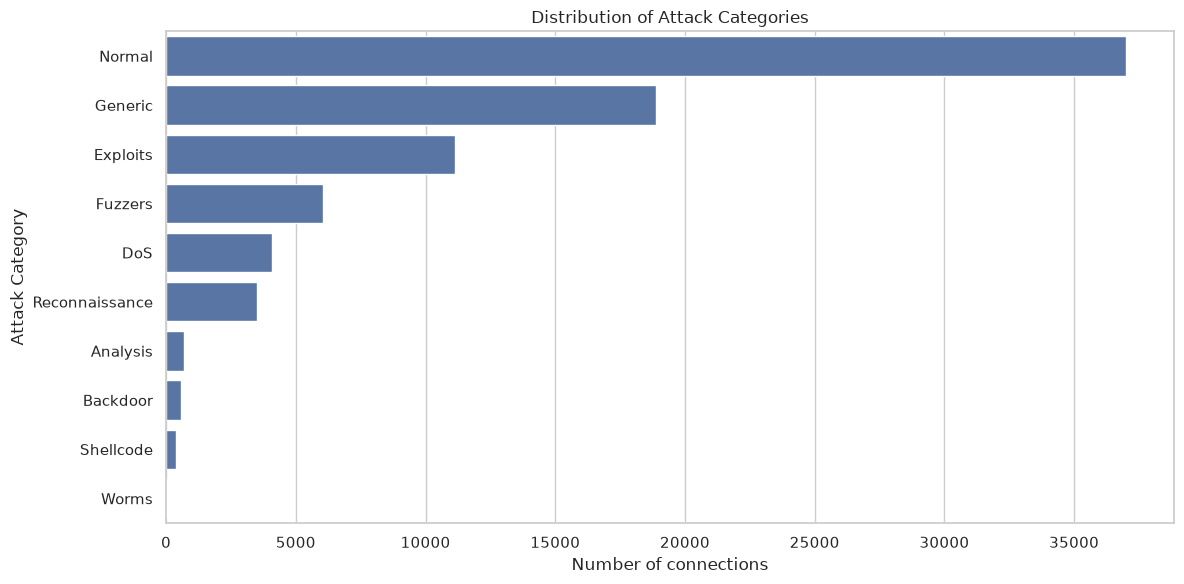

In [12]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=train,
    y="attack_cat",
    order=train["attack_cat"].value_counts().index
)

plt.title("Distribution of Attack Categories")
plt.xlabel("Number of connections")
plt.ylabel("Attack Category")
plt.tight_layout()
plt.show()

In [4]:
categorical_columns = train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

for column in categorical_columns:
    print(f"\n{column}:")
    print(train[column].value_counts().head(15))

Categorical columns: ['proto', 'service', 'state', 'attack_cat']

proto:
proto
tcp       43095
udp       29418
unas       3515
arp         987
ospf        676
sctp        324
any          96
gre          88
rsvp         64
ipv6         61
sep          58
sun-nd       54
mobile       52
swipe        52
pim          52
Name: count, dtype: int64

service:
service
-           47153
dns         21367
http         8287
smtp         1851
ftp          1552
ftp-data     1396
pop3          423
ssh           204
ssl            30
snmp           29
dhcp           26
radius          9
irc             5
Name: count, dtype: int64

state:
state
FIN    39339
INT    34163
CON     6982
REQ     1842
ACC        4
RST        1
CLO        1
Name: count, dtype: int64

attack_cat:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms 

In [5]:
categorical_features = ["proto", "service", "state"]

for col in categorical_features:
    print(f"\n{col}")
    print("Number of unique values:", train[col].nunique())
    print(train[col].value_counts().head(10))


proto
Number of unique values: 131
proto
tcp     43095
udp     29418
unas     3515
arp       987
ospf      676
sctp      324
any        96
gre        88
rsvp       64
ipv6       61
Name: count, dtype: int64

service
Number of unique values: 13
service
-           47153
dns         21367
http         8287
smtp         1851
ftp          1552
ftp-data     1396
pop3          423
ssh           204
ssl            30
snmp           29
Name: count, dtype: int64

state
Number of unique values: 7
state
FIN    39339
INT    34163
CON     6982
REQ     1842
ACC        4
RST        1
CLO        1
Name: count, dtype: int64


In [6]:
numeric_features = train.select_dtypes(
    include=np.number
).columns.tolist()

numeric_features = [
    col for col in numeric_features
    if col not in ["id", "label"]
]

print("Number of numerical features:", len(numeric_features))

display(train[numeric_features].describe().T)

Number of numerical features: 39


,count,mean,std,min,25%,50%,75%,max
dur,82332.0,1.006756e+00,4.710444e+00,0.0,0.000008,1.413800e-02,7.193603e-01,5.999999e+01
spkts,82332.0,1.866647e+01,1.339164e+02,1.0,2.000000,6.000000e+00,1.200000e+01,1.064600e+04
dpkts,82332.0,1.754594e+01,1.155741e+02,0.0,0.000000,2.000000e+00,1.000000e+01,1.101800e+04
sbytes,82332.0,7.993908e+03,1.716423e+05,24.0,114.000000,5.340000e+02,1.280000e+03,1.435577e+07
dbytes,82332.0,1.323379e+04,1.514715e+05,0.0,0.000000,1.780000e+02,9.560000e+02,1.465753e+07
rate,82332.0,8.241089e+04,1.486204e+05,0.0,28.606114,2.650177e+03,1.111111e+05,1.000000e+06
sttl,82332.0,1.809677e+02,1.015134e+02,0.0,62.000000,2.540000e+02,2.540000e+02,2.550000e+02
dttl,82332.0,9.571300e+01,1.166677e+02,0.0,0.000000,2.900000e+01,2.520000e+02,2.530000e+02
sload,82332.0,6.454902e+07,1.798618e+08,0.0,11202.466797,5.770032e+05,6.514286e+07,5.268000e+09
dload,82332.0,6.305470e+05,2.393001e+06,0.0,0.000000,2.112951e+03,1.585808e+04,2.082111e+07


In [7]:
numeric_data = train[numeric_features]

print("Infinite values:")
print(np.isinf(numeric_data).sum().sort_values(ascending=False).head(10))

print("\nNegative values:")
print((numeric_data < 0).sum().sort_values(ascending=False).head(10))

Infinite values:
dur       0
spkts     0
dpkts     0
sbytes    0
dbytes    0
rate      0
sttl      0
dttl      0
sload     0
dload     0
dtype: int64

Negative values:
dur       0
spkts     0
dpkts     0
sbytes    0
dbytes    0
rate      0
sttl      0
dttl      0
sload     0
dload     0
dtype: int64


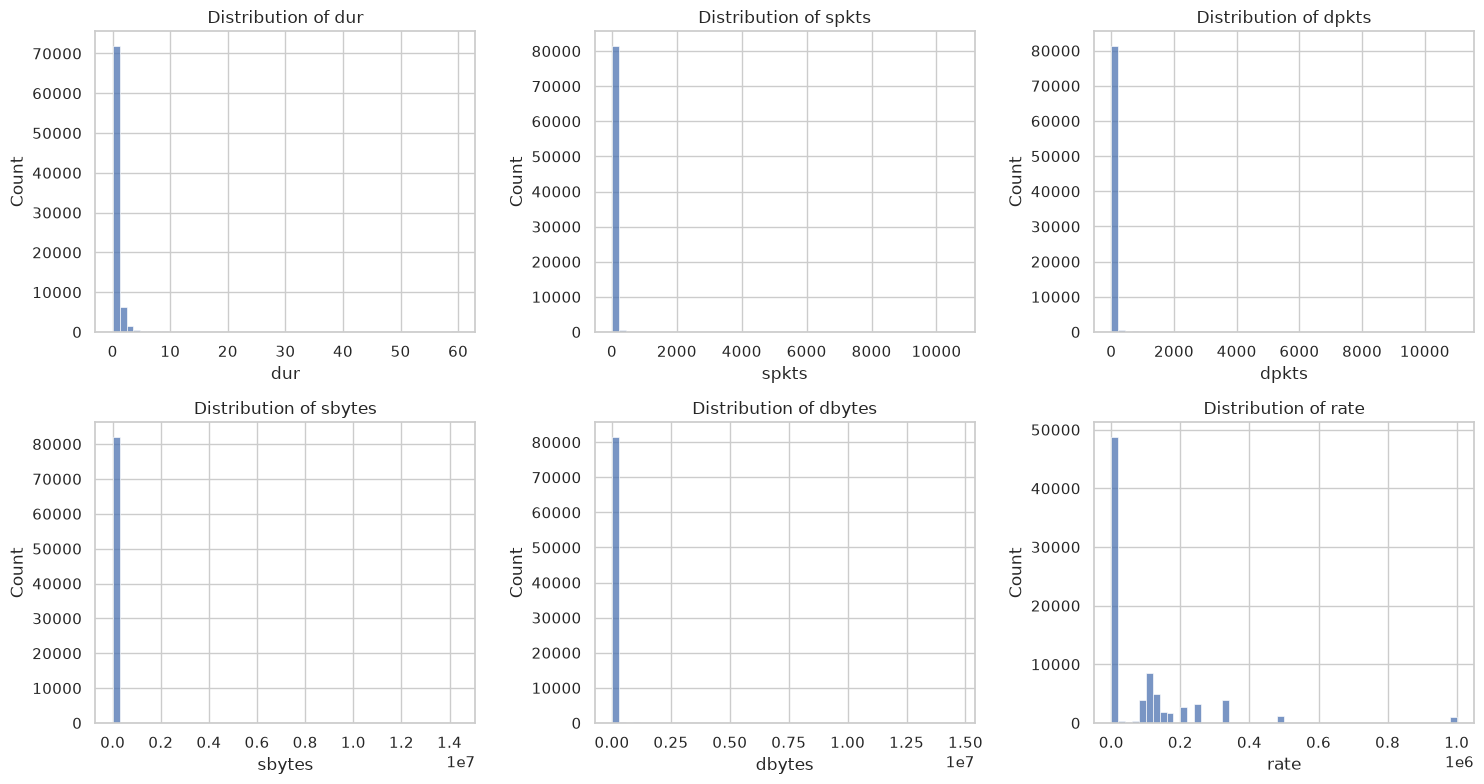

In [8]:
selected_features = [
    "dur",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), selected_features):
    sns.histplot(
        data=train,
        x=col,
        bins=50,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [20]:
print("Training attack categories:")
print(train["attack_cat"].value_counts())

print("\nTesting attack categories:")
print(test["attack_cat"].value_counts())

Training attack categories:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

Testing attack categories:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [9]:
categorical_features = ["proto", "service", "state"]

for col in categorical_features:
    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print(f"Unique values: {train[col].nunique()}")
    print(train[col].value_counts().to_string())


Feature: proto
Unique values: 131
proto
tcp            43095
udp            29418
unas            3515
arp              987
ospf             676
sctp             324
any               96
gre               88
rsvp              64
ipv6              61
sep               58
sun-nd            54
mobile            52
swipe             52
pim               52
prm               34
xns-idp           34
leaf-1            34
bbn-rcc           34
ggp               33
ip                33
ipnip             33
st2               33
argus             33
chaos             33
egp               33
emcon             33
nvp               33
pup               33
xnet              33
mux               33
dcn               33
hmp               33
trunk-1           33
trunk-2           33
leaf-2            33
irtp              33
rdp               33
netblt            33
cbt               33
igp               33
iso-tp4           33
mfe-nsp           32
merit-inp         32
3pc               32
idpr          

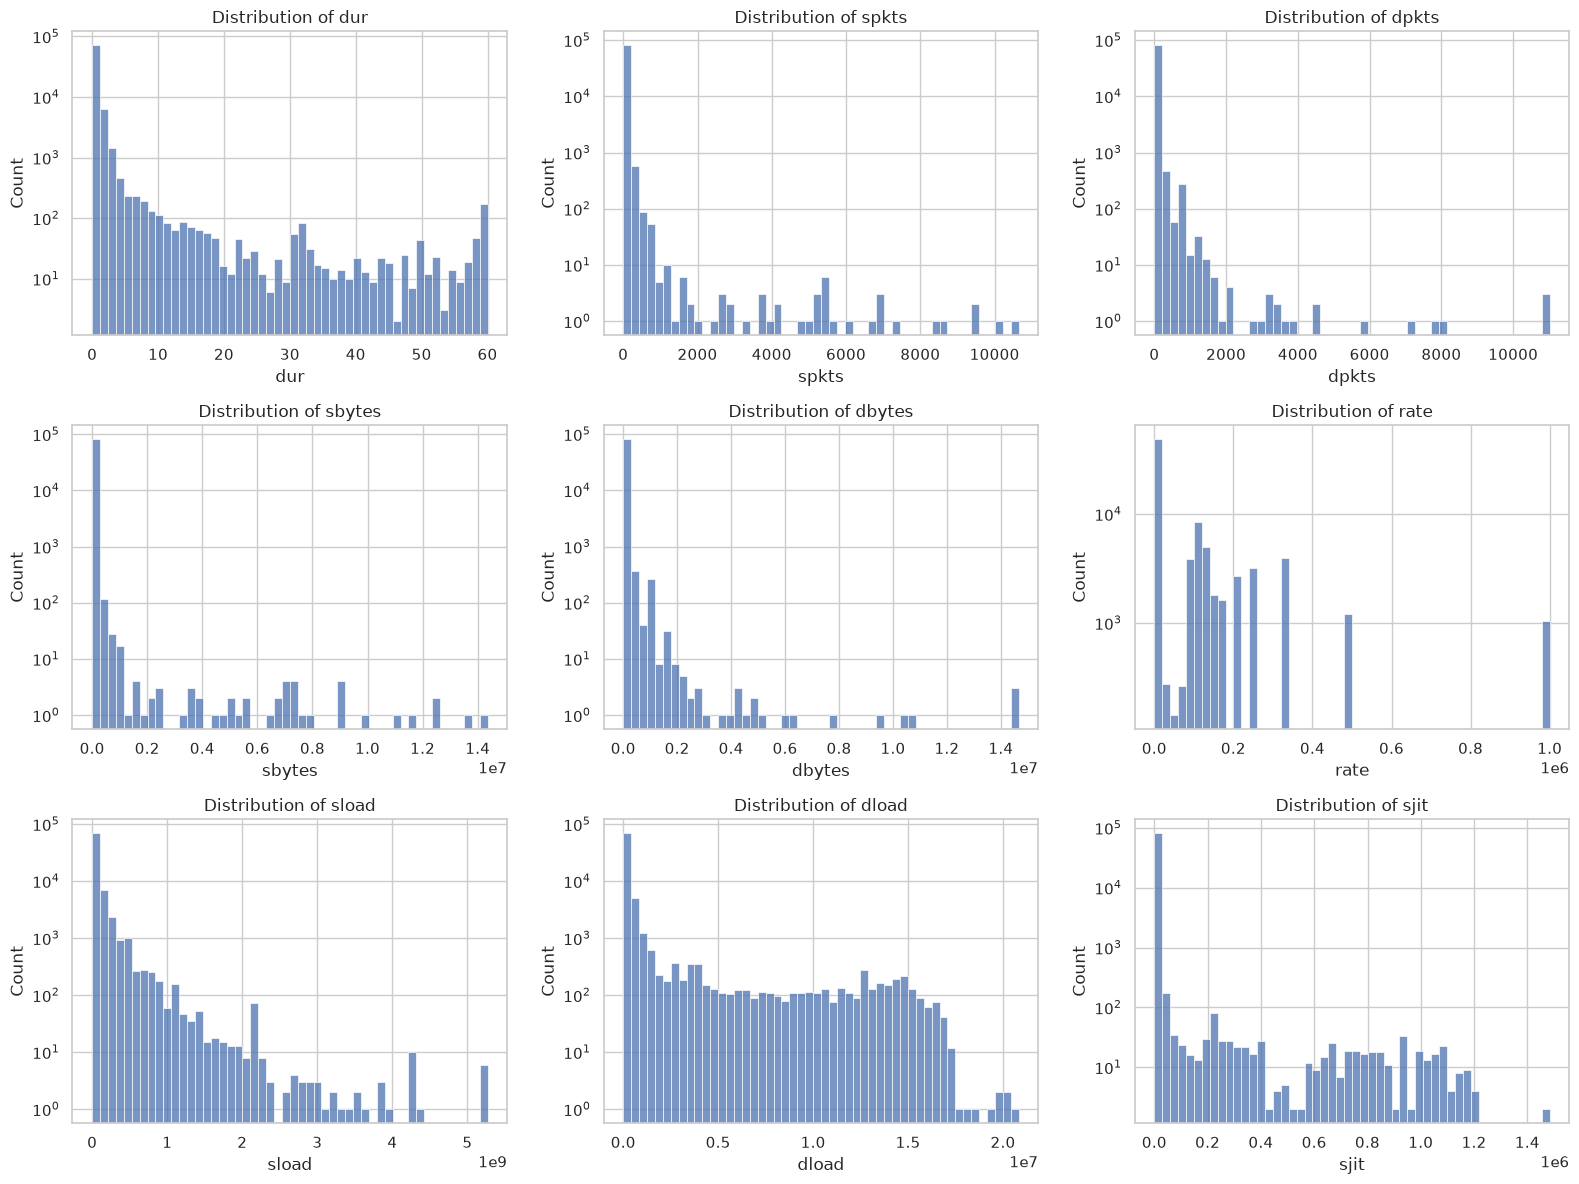

In [10]:
selected_features = [
    "dur",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate",
    "sload",
    "dload",
    "sjit"
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, col in zip(axes.flatten(), selected_features):
    sns.histplot(
        data=train,
        x=col,
        bins=50,
        ax=ax
    )
    ax.set_yscale("log")
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.savefig(
    "../results/figures/numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [11]:
tcp_features = ["stcpb", "dtcpb"]

display(train[tcp_features].describe().T)

print("Correlation between TCP sequence features:")
display(train[tcp_features].corr())

,count,mean,std,min,25%,50%,75%,max
stcpb,82332.0,1.084642e+09,1.390860e+09,0.0,0.0,27888855.0,2.171310e+09,4.294950e+09
dtcpb,82332.0,1.073465e+09,1.381996e+09,0.0,0.0,28569748.5,2.144205e+09,4.294881e+09


Correlation between TCP sequence features:


,stcpb,dtcpb
stcpb,1.000000,0.624463
dtcpb,0.624463,1.000000


In [12]:
skewness = train[numeric_features].skew().sort_values(
    ascending=False
)

display(skewness.to_frame(name="skewness"))

,skewness
trans_depth,170.794394
response_body_len,74.635200
djit,60.562275
dloss,54.465649
sbytes,53.778546
dbytes,52.550387
sloss,52.465277
dpkts,49.304127
spkts,47.747777
dinpkt,23.013046


In [11]:
print("Infinite values:", np.isinf(train[numeric_features]).sum().sum())
print("Negative values:", (train[numeric_features] < 0).sum().sum())

Infinite values: 0
Negative values: 0


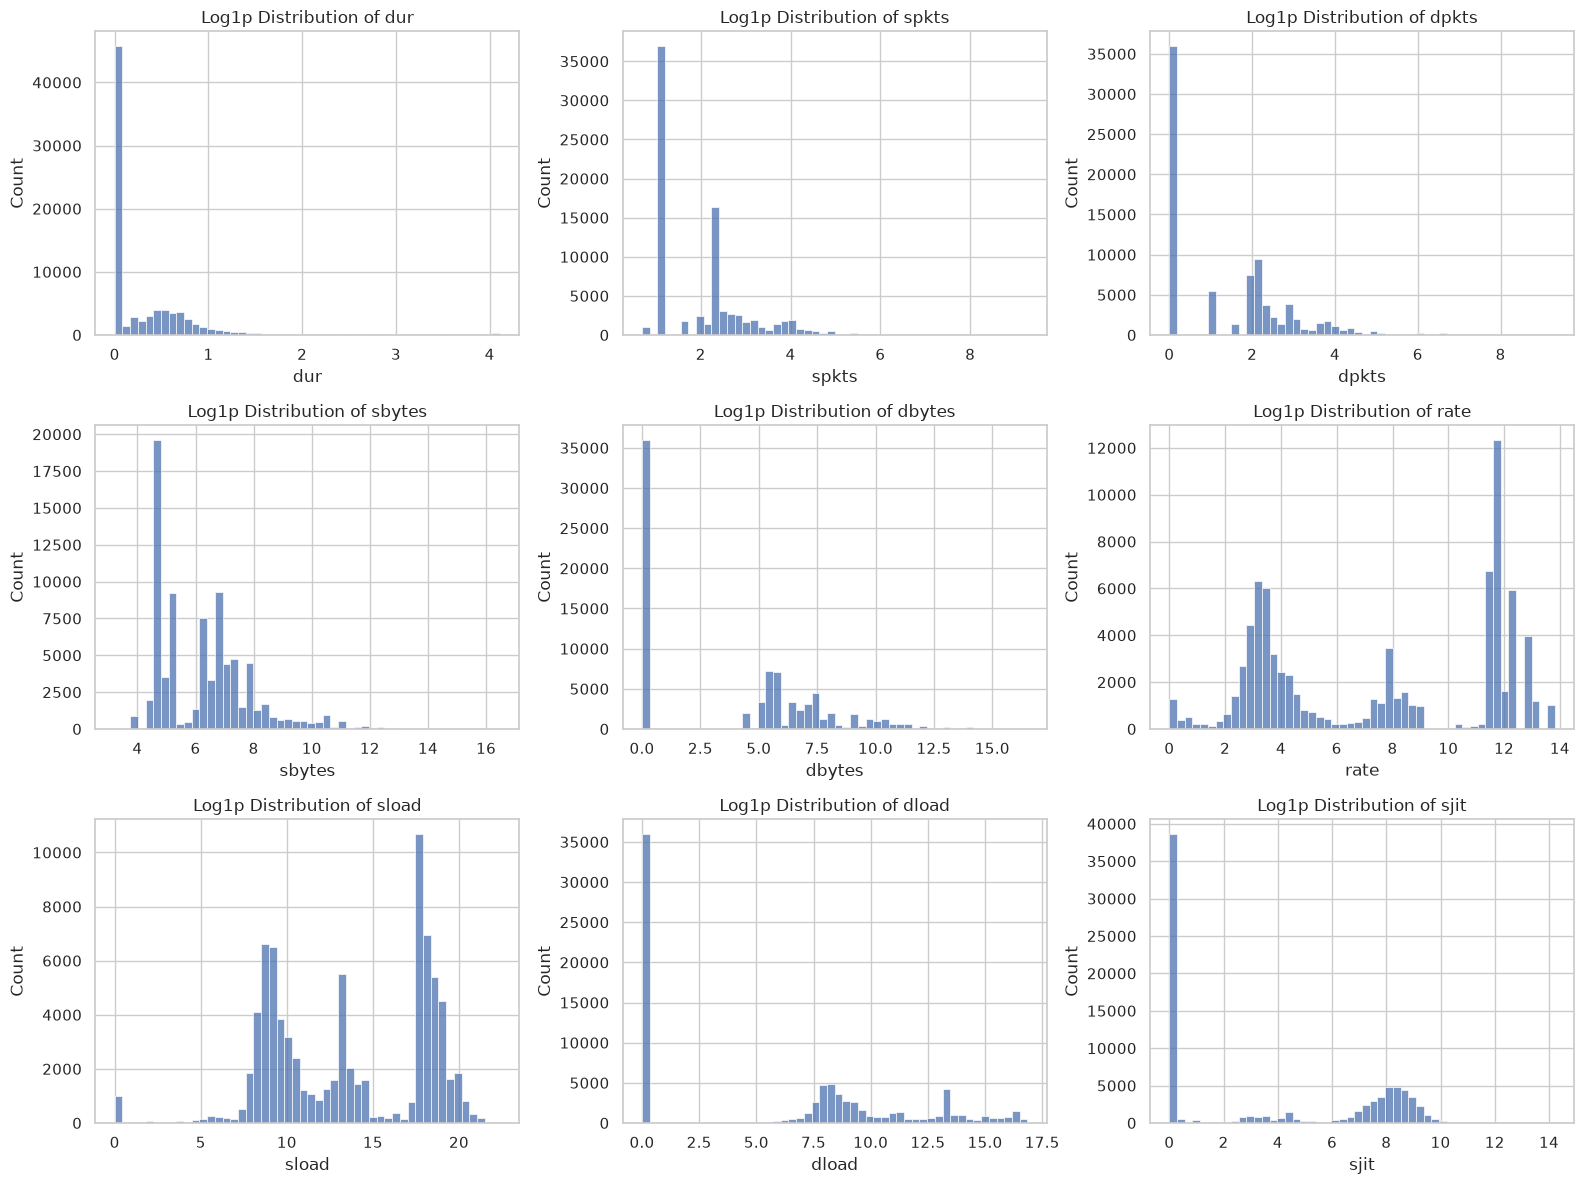

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, col in zip(axes.flatten(), selected_features):
    sns.histplot(np.log1p(train[col]), bins=50, ax=ax)
    ax.set_title(f"Log1p Distribution of {col}")

plt.tight_layout()


plt.savefig(
    "../results/figures/log1p_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
selected_features = [
    "dur",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate",
    "sload",
    "dload",
    "sjit",
    "djit"
]

skew_comparison = pd.DataFrame({
    "Original Skewness": train[selected_features].skew(),
    "Log1p Skewness": np.log1p(train[selected_features]).skew()
})

skew_comparison["Improvement"] = (
    skew_comparison["Original Skewness"].abs()
    - skew_comparison["Log1p Skewness"].abs()
)

display(skew_comparison.round(3))

,Original Skewness,Log1p Skewness,Improvement
dur,9.524,3.224,6.299
spkts,47.748,1.075,46.673
dpkts,49.304,0.693,48.611
sbytes,53.779,1.114,52.664
dbytes,52.550,0.249,52.301
rate,3.499,-0.033,3.466
sload,9.488,-0.254,9.234
dload,4.754,0.215,4.539
sjit,15.349,0.243,15.107
djit,60.562,0.690,59.872


In [20]:
for col in ["service", "state"]:
    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print(f"Unique values: {train[col].nunique()}")
    print(train[col].value_counts().to_string())


Feature: service
Unique values: 13
service
-           47153
dns         21367
http         8287
smtp         1851
ftp          1552
ftp-data     1396
pop3          423
ssh           204
ssl            30
snmp           29
dhcp           26
radius          9
irc             5

Feature: state
Unique values: 7
state
FIN    39339
INT    34163
CON     6982
REQ     1842
ACC        4
RST        1
CLO        1


In [14]:
print(train["state"].value_counts().to_string())

state
FIN    39339
INT    34163
CON     6982
REQ     1842
ACC        4
RST        1
CLO        1
